# Week 2: k-Nearest Neighbours Classification

# First time here?



1.   Copy this file to your Google Drive so you can edit it: **File->Save a copy in Drive** (requires a personal Google account)
2.   Done? Consider giving your copy a better name (e.g., including your name and/or student ID) - just click on the filename in the top left and edit it.
3.   (Want to re-open your copy in future? Go: **File->Open notebook** and select the Google Drive tab)
4.   (Want to find your file on your Google Drive? Google puts Colab files in a folder called "Colab Notebooks")

# Scikit-learn implementations (k-NN)

In this notebook we're going to focus on using an existing k-Nearest Neighbours (k-NN) implementation: the one provided by the [Scikit-learn](https://scikit-learn.org/stable/) package.

As well as learning how to use it, we'll introduce some different methods for evaluating and interpreting the models it produces.

## Basic supervised learning recipe

The code below shows our basic supervised learning recipe again. We're using it to train and evaluate on the iris.csv data again, but this time we're using [Scikit-learn](https://scikit-learn.org/stable/)'s k-NN classifier implementation.

*   How accurate is the model? **type your answer here**

In [10]:
# Import the packages we use
import pandas as pd
import numpy as np
from sklearn.neighbors import KNeighborsClassifier

# Load all the observations from file
observations = pd.read_csv('https://helward.mmu.ac.uk/STAFF/J.Darby/ML/iris.csv')

# Set the name of the target feature
target_feature = 'species'

# Shuffle all the observations
observations_shuffled = observations.sample(frac=1, random_state=99)

# Set the fraction of observations we will use for testing
testing_fraction = 0.4
split_index = int(observations_shuffled.shape[0] * testing_fraction)

# Split into testing observations and training observations ("horizontal split")
observations_test = observations_shuffled.iloc[:split_index]
observations_train = observations_shuffled.iloc[split_index:]

# Split into testing examples and testing labels ("vertical split")
test_examples = observations_test.drop(columns=target_feature).to_numpy()
test_labels = observations_test[target_feature].to_numpy()

# Split into training examples and training labels ("vertical split")
train_examples = observations_train.drop(columns=target_feature).to_numpy()
train_labels = observations_train[target_feature].to_numpy()

# Create a k-NN classification model
model = KNeighborsClassifier()

# Call the model's fitting/training algorithm, passing in our training examples and training labels
model.fit(train_examples, train_labels)

# Use the trained model to generate predictions based on our testing examples
predictions = model.predict(test_examples)

# Find the total number of model predictions that matched with their corresponding testing labels
correct_predictions = sum(predictions == test_labels)
# Calculate the model's accuracy: the fraction of predictions that were correct
accuracy = correct_predictions / len(test_labels)
# Display the accuracy as a single quantitative measure of overall performance
print("Accuracy:", accuracy, "(or", round(accuracy*100, 1), "%)")

Accuracy: 0.9666666666666667 (or 96.7 %)


## Check the docs

Regardless of how confident you feel with the theory behind a particular model, the important thing is still to be able to use it to get results (particularly for 2CWK50).

Let's spend some time looking at the Scikit-learn documentation for the k-NN classification model, and focusing particularly on the aspects of the class that are common to other classification models we'll meet.

Find the documentation page for the relevant class and **add the link here**: [link text](https://) (**Double click to edit**)

**Tip**: Often you know the name of the model you want to use, but not the name of the specific class. A quick Google for "sklearn" (a common abbreviation of Scikit-learn), plus the name of the model, plus the kind of problem you're working on will typically do the trick. E.g., here "sklearn k-nearest neighbours classification". (Or of course you can ask your favourite large language model (YFLLM).)


## Class constructor

First, have a quick look over the class constructor's arguments at the top of the documentation page. There's no need to read them all in detail, just have a look at the first one, which you'll hopefully recognise.

The Scikit-learn documentation calls arguments "parameters" (another commonly used term for the values passed to any function/method/constructor). Just note that they are not "parameters" in the supervised learning sense (values defining how the model makes its predictions). They are typically "hyperparameters". Hyperparameters are constant values which we set before running a model's `.fit()` method, and which have an impact on what parameters are recovered.

To minimise the potential for confusion, we'll talk about "arguments" to constructors/methods in this notebook (instead of "parameters").

In the case of k-NN, the most interesting hyperparameter gives us control over k, the number of nearest neighbours (or most similar training examples) that the model considers during prediction.

*    **What is the name of the constructor argument that lets us set this value?** `n_neighbors`

For other models, the constructor arguments will give us access to different hyperparameters (specific to each model), but, broadly speaking, they all allow us some control over the complexity of the model, and how accurately it is allowed to describe the training data.

If we don't set hyperparameter values, then any good implementation (like Scikit-learn's) will use sensible default values for us. For example, we don't set the value of k (the number of nearest neighbours) in our code listing above:

*    **What is the default value for this argument?** **5**

If ever you're unsure about how the hyperparameters of a particular model work, it's always fine just to call its constructor with no extra arguments, and this will produce a sensible set of defaults.

```
# This empty call to any model's constructor will always result in sensible hyperparameter defaults
model = AnyClassifier()
```

In [11]:
import pandas as pd

# Load the biopsies.csv data
biopsies_df = pd.read_csv('https://helward.mmu.ac.uk/STAFF/J.Darby/ML/biopsies.csv')

# Calculate the number of observations (rows)
num_observations = biopsies_df.shape[0]

# The target feature 'diagnosis' is mentioned in the notebook content (MYL_pWikmqeI).
# Number of predictive features is total columns - 1 (for the target feature).
# Let's confirm the target feature and other columns first.

print("Columns in biopsies.csv:", biopsies_df.columns.tolist())

# Assuming 'diagnosis' is the target feature based on context
target_feature_name = 'diagnosis'

# Filter out the target feature to count only predictive features
predictive_features_df = biopsies_df.drop(columns=[target_feature_name])
num_predictive_features = predictive_features_df.shape[1]

print(f"Number of observations: {num_observations}")
print(f"Number of predictive features: {num_predictive_features}")
print(f"Name of the target feature: {target_feature_name}")

# Display the first few rows to confirm data structure
display(biopsies_df.head())

Columns in biopsies.csv: ['diagnosis', 'radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean', 'concave points_mean', 'symmetry_mean', 'fractal_dimension_mean', 'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se', 'compactness_se', 'concavity_se', 'concave points_se', 'symmetry_se', 'fractal_dimension_se', 'radius_worst', 'texture_worst', 'perimeter_worst', 'area_worst', 'smoothness_worst', 'compactness_worst', 'concavity_worst', 'concave points_worst', 'symmetry_worst', 'fractal_dimension_worst']
Number of observations: 569
Number of predictive features: 30
Name of the target feature: diagnosis


,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,Benign,13.540,14.36,87.46,566.3,0.09779,0.08129,0.06664,0.047810,0.1885,...,15.110,19.26,99.70,711.2,0.14400,0.17730,0.23900,0.12880,0.2977,0.07259
1,Benign,13.080,15.71,85.63,520.0,0.10750,0.12700,0.04568,0.031100,0.1967,...,14.500,20.49,96.09,630.5,0.13120,0.27760,0.18900,0.07283,0.3184,0.08183
2,Benign,9.504,12.44,60.34,273.9,0.10240,0.06492,0.02956,0.020760,0.1815,...,10.230,15.66,65.13,314.9,0.13240,0.11480,0.08867,0.06227,0.2450,0.07773
3,Benign,13.030,18.42,82.61,523.8,0.08983,0.03766,0.02562,0.029230,0.1467,...,13.300,22.81,84.46,545.9,0.09701,0.04619,0.04833,0.05013,0.1987,0.06169
4,Benign,8.196,16.84,51.71,201.9,0.08600,0.05943,0.01588,0.005917,0.1769,...,8.964,21.96,57.26,242.2,0.12970,0.13570,0.06880,0.02564,0.3105,0.07409


### 1CWK50 note

If you spotted the `algorithm` hyperparameter in the docs, then don't worry about it for the 1CWK50 coursework. Some of the options under the default `'auto'` behaviour can, for certain data, cause the `fit()` method to build complex data structures in order that nearest neighbours can be found more quickly by the `predict()` method. You don't need to worry about these options, you can just explain the conceptually simple `'brute'` (force) option - where new testing examples are always compared against _all_ the training examples in order to find the k most similar.


## Class methods

Have a look at the class methods next. These are listed towards the end of the documentation, after the **Notes** and **Examples** sections.

Though there may be some methods that are specific to the type of model we're training, the three most important methods are common to all classification models:

1. `fit()` - runs an algorithm to learn model parameters from a set of training examples and training labels (paying attention to the hyperparameter values)
2. `predict()` - takes a new set of testing examples and, for each one, uses the model's parameters to generate a predicted label (requires that we've run `fit()` first)
3. `predict_proba()` - takes a new set of testing examples and, for each one, uses the model's parameters to generate probabilities for every possible label

We already called the `.fit()` method for our k-NN classifier in the code cell above. Below, we add some code to print out:
1. The predicted label for the first testing example;
2. The probability of the first testing example being associated with each of the possible labels in the problem.

**Tip**: Note we have to use slice notation to grab the first example (a single row) as a 2D array (rather than a 1D array).

**Tip**: for part 2, probabilities range between 0-1 and so the model is *certain* about its prediction. Read on to find out about the ordering of the three probabilities.

In [9]:
print(model.predict(test_examples[0:1,:]))
print(model.predict_proba(test_examples[0:1,:]))

['Class B']
[[0. 1.]]


## Class instance attributes

Last, have a quick look at the class instance attributes. These are listed in the middle of the documentation, just after the **Parameters** section.

Many of these values don't get set until the `fit()` method has been called, hence us looking at them last. Most of them are nice-to-have bits of information about the training data that are useful to have access to but not critical.

**Tip**: The Scikit-learn package uses the convention of a trailing underscore to name attributes that won't become available until after the `fit()` method is called.

The `.classes_` instance attribute holds a record of the unique labels seen by the model's `.fit()` method. The ordering of the labels in this attribute (simple alphabetical) is often re-used by the model - for example, in the ordering of the probabilities output by the `predict_proba()` method above.

We add some code below to print out the `.classes_` attribute for our k-NN model:

In [8]:
print(model.classes_)

['Class A' 'Class B']


# The biopsies.csv data

Let's try working with some more interesting and challenging data. The biopsies.csv data contains a set of simple measurements automatically extracted from human tissue biopsies by a computer system, and eventual clinical diagnoses for each patient (either Benign/safe, or Malignant/dangerous). The interesting question is whether supervised learning could be used to allow for fast and reliable diagnosis based on the automatic measurements.

We keep a copy of the biopsies data on an MMU web server for easy access and use in these labs: [biopsies.csv](https://helward.mmu.ac.uk/STAFF/J.Darby/ML/biopsies.csv)

Click the link to download the .csv file to your local machine, and open it up in Excel to have a look. Complete the questions below:

1.   How many **observations** are there? **569**
2.   How many **features** are there? **30**
3.   What is the name of the **target feature**? **diagnosis**

**Tip**: remember there's a terminology document on Moodle if you need to check it ([direct link](https://moodle.mmu.ac.uk/pluginfile.php/8495867/mod_page/content/16/ML-2526-terminology.pdf))

## You try: k-NN

Copy/paste the original code listing into the code cell below, and adjust it to train and evaluate on the biopsies.csv data.

*   How accurate was the model? **95.2%**

**Tip**: You should only need to edit two lines of the original code listing to get it working.

In [12]:
# Import the packages we use
import pandas as pd
import numpy as np
from sklearn.neighbors import KNeighborsClassifier

# Load all the observations from file
observations = pd.read_csv('https://helward.mmu.ac.uk/STAFF/J.Darby/ML/biopsies.csv')

# Set the name of the target feature
target_feature = 'diagnosis'

# Shuffle all the observations
observations_shuffled = observations.sample(frac=1, random_state=99)

# Set the fraction of observations we will use for testing
testing_fraction = 0.4
split_index = int(observations_shuffled.shape[0] * testing_fraction)

# Split into testing observations and training observations ("horizontal split")
observations_test = observations_shuffled.iloc[:split_index]
observations_train = observations_shuffled.iloc[split_index:]

# Split into testing examples and testing labels ("vertical split")
test_examples = observations_test.drop(columns=target_feature).to_numpy()
test_labels = observations_test[target_feature].to_numpy()

# Split into training examples and training labels ("vertical split")
train_examples = observations_train.drop(columns=target_feature).to_numpy()
train_labels = observations_train[target_feature].to_numpy()

# Create a k-NN classification model with n_neighbors set to 10
model = KNeighborsClassifier(n_neighbors=10)

# Call the model's fitting/training algorithm, passing in our training examples and training labels
model.fit(train_examples, train_labels)

# Use the trained model to generate predictions based on our testing examples
predictions = model.predict(test_examples)

# Find the total number of model predictions that matched with their corresponding testing labels
correct_predictions = sum(predictions == test_labels)
# Calculate the model's accuracy: the fraction of predictions that were correct
accuracy = correct_predictions / len(test_labels)
# Display the accuracy as a single quantitative measure of overall performance
print("Accuracy:", accuracy, "(or", round(accuracy*100, 1), "%)")

Accuracy: 0.920704845814978 (or 92.1 %)


## You try: adjusting a hyperparameter

Try adjusting the value of k (the number of nearest neighbours) to be 10.

*   How accurate was the model? **92.1%**

## You try: standardisation

k-NN is one of a number of models we'll meet that is sensitive to the relative ranges over which individual predictive feature values vary. With data like iris.csv this doesn't matter, as all the predictive features vary over a similar range (a few cm). But for data like biopsies.csv we really need to do some pre-processing of our data to bring the feature value ranges into a similar range.

The code below applies z-score standardisation (ensuring all predictive features have a mean of 0 and a standard deviation of 1). You've hopefully seen the approach before. (Note it's important to learn the transform from the training data only, so that no information about the testing data "leaks" into the model.)

You are free to copy/paste the code and use it in your own work on the module.

*    **Try adding the code snippet to your previous code listing, making sure you put it in the right place (the first comment helps you)**
*    **Update your previous records of how accurate the model is (you can leave the old scores in brackets)**



In [ ]:
from sklearn.preprocessing import StandardScaler

# ...After splitting your data and before fitting your model...

# Create a new StandardScaler object, ready to do z-score standardisation
scaler = StandardScaler()
# Compute means and standard deviations for each feature in the training data
scaler.fit(train_examples)
# Divide individual feature values in the training data by their respective means and standard deviations:
train_examples = scaler.transform(train_examples)
# Apply the same transformation to the testing examples
test_examples = scaler.transform(test_examples)

# Hyperparameter investigation

Let's try automating a simple investigation into how performance changes with value of k on the biopsies.csv data.

Instead of re-constructing our model objects in order to change a constructor argument, we can call the `set_params()` method. Again it's a slightly unfortunate naming convention, as we're typically changing hyperparameters, but it's a very useful method nonetheless.

We just have to remember to call the `.fit()` method again after making the change. See the example below:

In [2]:
# Change the number of nearest neighbours our model is using
model.set_params(n_neighbors=15)

# Fit the model to our training data
model.fit(train_examples, train_labels)

KNeighborsClassifier(n_neighbors=15)

Now have a look at the code below which uses a for loop to produce a simple investigation into different k-values, and check you can run it and follow what's happening:

In [3]:
# Import the packages we use
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier

# Load all the observations from file
observations = pd.read_csv('https://helward.mmu.ac.uk/STAFF/J.Darby/ML/biopsies.csv')

# Set the name of the target feature
target_feature = 'diagnosis'

# Shuffle all the observations
observations_shuffled = observations.sample(frac=1, random_state=99)

# Set the fraction of observations we will use for testing
testing_fraction = 0.4
split_index = int(observations_shuffled.shape[0] * testing_fraction)

# Split into testing observations and training observations ("horizontal split")
observations_test = observations_shuffled.iloc[:split_index]
observations_train = observations_shuffled.iloc[split_index:]

# Split into testing examples and testing labels ("vertical split")
test_examples = observations_test.drop(columns=target_feature).to_numpy()
test_labels = observations_test[target_feature].to_numpy()

# Split into training examples and training labels ("vertical split")
train_examples = observations_train.drop(columns=target_feature).to_numpy()
train_labels = observations_train[target_feature].to_numpy()

# ...After splitting your data and before fitting your model...

# Create a new StandardScaler object, ready to do z-score standardisation
scaler = StandardScaler()
# Compute means and standard deviations for each feature in the training data
scaler.fit(train_examples)
# Divide individual feature values in the training data by their respective means and standard deviations:
train_examples = scaler.transform(train_examples)
# Apply the same transformation to the testing examples
test_examples = scaler.transform(test_examples)

# Define the range of hyperparameter values we're interested in
k_vals = list(range(1, 30, 2))
# And a list to hold the resulting accuracies
accuracies = []

# Create a k-NN classification model
model = KNeighborsClassifier()

for k in k_vals:

  # Update the number of nearest neighbours our model is using
  model.set_params(n_neighbors=k)

  # Call the model's fitting/training algorithm, passing in our training examples and training labels
  model.fit(train_examples, train_labels)

  # Use the trained model to generate predictions based on our testing examples
  predictions = model.predict(test_examples)

  # Find the total number of model predictions that matched with their corresponding testing labels
  correct_predictions = sum(predictions == test_labels)
  # Calculate the model's accuracy: the fraction of predictions that were correct
  accuracy = correct_predictions / len(test_labels)
  # Display the accuracy as a single quantitative measure of overall performance
  print("Accuracy:", accuracy, "(or", round(accuracy*100, 1), "%)")

  # Store this latest accuracy result
  accuracies.append(accuracy)

Accuracy: 0.9515418502202643 (or 95.2 %)
Accuracy: 0.973568281938326 (or 97.4 %)
Accuracy: 0.960352422907489 (or 96.0 %)
Accuracy: 0.973568281938326 (or 97.4 %)
Accuracy: 0.9647577092511013 (or 96.5 %)
Accuracy: 0.973568281938326 (or 97.4 %)
Accuracy: 0.9647577092511013 (or 96.5 %)
Accuracy: 0.9559471365638766 (or 95.6 %)
Accuracy: 0.960352422907489 (or 96.0 %)
Accuracy: 0.9559471365638766 (or 95.6 %)
Accuracy: 0.9559471365638766 (or 95.6 %)
Accuracy: 0.9559471365638766 (or 95.6 %)
Accuracy: 0.9559471365638766 (or 95.6 %)
Accuracy: 0.9559471365638766 (or 95.6 %)
Accuracy: 0.9647577092511013 (or 96.5 %)


# Matplotlib

Displaying accuracies as debug works pretty well, and we could improve the debug to print out the hyperparameter values alongside each accuracy. However, it's still quite easy to make a mistake when eyeballing this kind of text-based output.

A good alternative is to produce a simple graphical visualisation of the accuracy scores versus the hyperparameter values. This can let you review results (and, for example, choose the optimal hyperparameter setting) more easily.

In the code cell below, we use the [Matplotlib](https://matplotlib.org/stable/) plotting package to graph the results of the previous hyperparameter investigation using the [implicit interface](https://matplotlib.org/stable/users/explain/quick_start.html#the-explicit-and-the-implicit-interfaces).

**Tip**: Notice there's a new `import` statement at the top to support the generation of the plot.

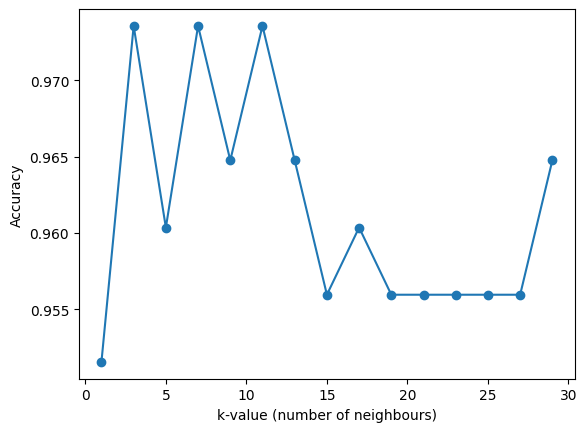

In [4]:
# Import the packages we need
import matplotlib.pyplot as plt

# Show evaluation results graphically
plt.figure()
plt.plot(k_vals, accuracies, marker='o', linestyle='-')
plt.xlabel('k-value (number of neighbours)')
plt.ylabel('Accuracy')
plt.show()

```markdown
# Confusion matrices

Accuracy is a useful guide to how a model is performing, but a model can get the same accuracy score in many different ways. A confusion matrix gives us a breakdown of what happened for the individual labels in our problem.

Check you can interpret a confusion matrix by looking at the code example below and answering the questions.

The code example imports a `confusion_matrix` function from Scikit-learn's `metrics` submodule to do the work for us.

There's also an `accuracy_score` function available in the same submodule and we use this to do our accuracy calculation for us as well.

**Note we've reverted to processing the iris.csv data for this example**:

*    How many Versicolor irises were incorrectly classified as Virginica irises? **1**
*    How many Setosa irises were correctly classified? **17**
*    How many Virginica irises were in the testing data? **21**

**Tip**: the rows/columns labels for the matrix aren't shown, but they are just the class labels in your problem, sorted in alphabetical order. (Remember these are stored in the `classes_` attribute if you want to print them as a reminder.)

**Tip**: you read across a row to see what happened to all the testing examples in a given class (e.g., the first row shows how the model classified the 'setosa' irises that were present in the testing data)

In [5]:
# Import the packages we use
import pandas as pd
import numpy as np
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix, accuracy_score

# Load all the observations from file
observations = pd.read_csv('https://helward.mmu.ac.uk/STAFF/J.Darby/ML/iris.csv')

# Set the name of the target feature
target_feature = 'species'

# Shuffle all the observations
observations_shuffled = observations.sample(frac=1, random_state=99)

# Set the fraction of observations we will use for testing
testing_fraction = 0.4
split_index = int(observations_shuffled.shape[0] * testing_fraction)

# Split into testing observations and training observations ("horizontal split")
observations_test = observations_shuffled.iloc[:split_index]
observations_train = observations_shuffled.iloc[split_index:]

# Split into testing examples and testing labels ("vertical split")
test_examples = observations_test.drop(columns=target_feature).to_numpy()
test_labels = observations_test[target_feature].to_numpy()

# Split into training examples and training labels ("vertical split")
train_examples = observations_train.drop(columns=target_feature).to_numpy()
train_labels = observations_train[target_feature].to_numpy()

# Create a k-NN classification model
model = KNeighborsClassifier()

# Call the model's fitting/training algorithm, passing in our training examples and training labels
model.fit(train_examples, train_labels)

# Use the trained model to generate predictions based on our testing examples
predictions = model.predict(test_examples)

# Calculate the model's accuracy: the fraction of predictions that were correct
accuracy = accuracy_score(test_labels, predictions)
# Display the accuracy as a single quantitative measure of overall performance
print("Accuracy:", accuracy, "(or", round(accuracy*100, 1), "%)")

# Display a confusion matrix showing a breakdown of results for each label
print(confusion_matrix(test_labels, predictions))

Accuracy: 0.9666666666666667 (or 96.7 %)
[[17  0  0]
 [ 0 21  1]
 [ 0  1 20]]


# The moons.csv data

Let's introduce one final group of data: moons.csv. This is synthetic data where the challenge is to predict the "Label" feature (which has possible values of either "Class A" or "Class B") from two predictive feature values.

We keep a copy of the moons data on an MMU web server for easy access and use in these labs: [moons.csv](https://helward.mmu.ac.uk/STAFF/J.Darby/ML/moons.csv)

Click the link to download the .csv file to your local machine, and open it up in Excel to have a quick look.

## Feature space visualisation

Hopefully you came across the concept of "feature space" in your research this week. This is where we visualise our data by plotting individual examples as points on a graph, with one axis dedicated to each predictive feature value.

Feature spaces are hard to think about for high-dimensional problems (with lots of predictive features) but for low-dimensional problems with just 2 or 3 predictive features -- like the moons.csv data -- we can plot the graph.

Below, we use Matplotlib's `scatter()` method to generate a feature space plot of our training data - have a read over the code and then run to see the result:


<Figure size 640x480 with 0 Axes>

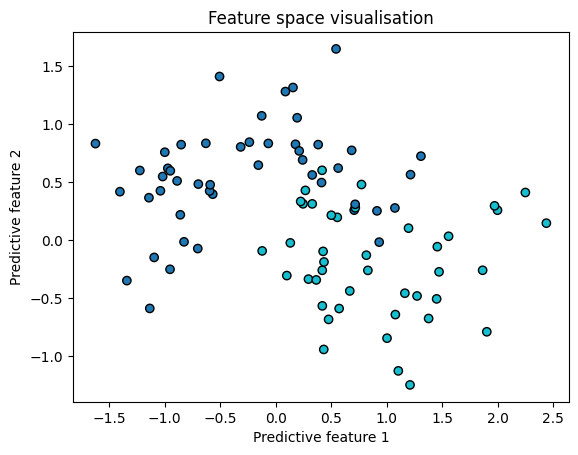

In [6]:
# Import the packages we use
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load all the observations from file
observations = pd.read_csv('https://helward.mmu.ac.uk/STAFF/J.Darby/ML/moons.csv')

# Set the name of the target feature
target_feature = 'Label'

# Shuffle all the observations
observations_shuffled = observations.sample(frac=1, random_state=99)

# Set the fraction of observations we will use for testing
testing_fraction = 0.4
split_index = int(observations_shuffled.shape[0] * testing_fraction)

# Split into testing observations and training observations ("horizontal split")
observations_test = observations_shuffled.iloc[:split_index]
observations_train = observations_shuffled.iloc[split_index:]

# Split into testing examples and testing labels ("vertical split")
test_examples = observations_test.drop(columns=target_feature).to_numpy()
test_labels = observations_test[target_feature].to_numpy()

# Split into training examples and training labels ("vertical split")
train_examples = observations_train.drop(columns=target_feature).to_numpy()
train_labels = observations_train[target_feature].to_numpy()

# Visualise training data in feature space
plt.figure()

# Matplotlib wants integers for the colour codes in our scatter plot: convert our string-based labels over
unique_labels, train_labels_int = np.unique(train_labels, return_inverse=True)
# Show evaluation results graphically
plt.figure()
# Plot the training data
plt.scatter(train_examples[:, 0], train_examples[:, 1], c=train_labels_int, edgecolors='black', cmap='tab10')

plt.xlabel('Predictive feature 1')
plt.ylabel('Predictive feature 2')
plt.title('Feature space visualisation')
plt.show()

## Generalisation visualisation

If we can plot the feature space, then we can also visualise how a model's `fit()` method has generalised based on our training data. I.e., for every possible coordinate in the feature space, what label would the model predict? (In practice we typically only look at a region that spans the original training data.)

The code below produces this visualisation for a k-NN model trained on the moons.csv data. It first covers the feature space in a dense grid of testing examples. It then passes those testing examples to the model to generate predicted labels. Finally it plots the grid, colour-coded by the resulting predictions. (It also superimposes the training data on top of the grid, for extra context.)

*    **Try adjusting the code to produce visualisations for some different k-values (try a very low value and a very high value)**

**Note**: Scikit-learn has some built-in functionality for generalisation visualisation but it can't do all the things we'll need in later weeks, hence us introducing our own approach here.

<Figure size 640x480 with 0 Axes>

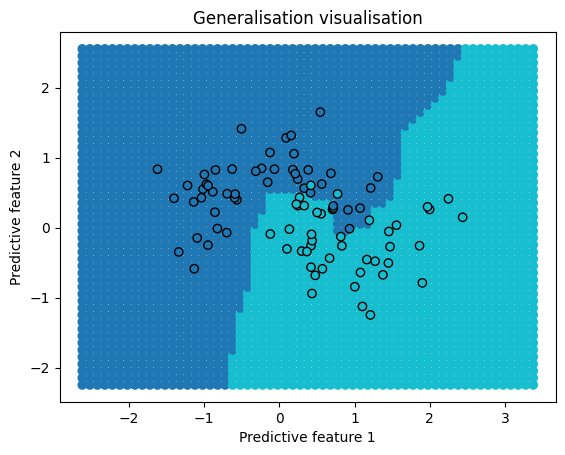

In [7]:
# Import the packages we use
import numpy as np
import matplotlib.pyplot as plt

# Create a k-NN classification model
model = KNeighborsClassifier()

# Call the model's fitting/training algorithm, passing in our training examples and training labels
model.fit(train_examples, train_labels)

# Prepare our own grid of testing examples to use in visualization
x_min = train_examples[:, 0].min() - 1
x_max = train_examples[:, 0].max() + 1
y_min = train_examples[:, 1].min() - 1
y_max = train_examples[:, 1].max() + 1
# adjust this to get more/less definition in the grid (takes more/less time, may need smaller plot points below)
jump = 0.1
# Get help from numpy's meshgrid() function to be fast
grid_x, grid_y = np.meshgrid(np.arange(x_min, x_max, jump), np.arange(y_min, y_max, jump))
# Turn the results back into a deep table with only 2 columns
grid_examples = np.c_[grid_x.ravel(), grid_y.ravel()]

# Make predictions for each of the examples in the grid
grid_predictions = model.predict(grid_examples)

# Visualise the final generalisation
plt.figure()

# Matplotlib wants integers for the colour codes in our scatter plot: convert our string-based labels over
unique_labels, grid_labels_int = np.unique(grid_predictions, return_inverse=True)
# Show evaluation results graphically
plt.figure()
# Plot the generalisation
plt.scatter(grid_examples[:, 0], grid_examples[:, 1], c=grid_labels_int, cmap='tab10')
# Plot the training data
plt.scatter(train_examples[:, 0], train_examples[:, 1], c=train_labels_int, edgecolors='black', cmap='tab10')

plt.xlabel('Predictive feature 1')
plt.ylabel('Predictive feature 2')
plt.title('Generalisation visualisation')
plt.show()

# General k-NN properties

We've seen a number of ways to train and interpret different k-NN models on different sets of data. But k-NN models do have some more general properties that are worth being aware of, and taking into consideration alongside any experimental results you generate.

*    **Make a list of general k-NN strengths and weaknesses**

Strengths:
1. Simple and intuitive algorithm, easy to understand and implement.
2. No explicit training phase; model adapts easily to new training data.
3. Can be used for both classification and regression problems.
4. Effective for datasets with non-linear decision boundaries.

Weaknesses:
1. Computationally expensive during prediction, especially with large datasets.
2. Sensitive to noisy data and outliers, which can heavily influence predictions.
3. Performance degrades with high-dimensional data (curse of dimensionality) and irrelevant features.
4. Requires feature scaling (e.g., standardization or normalization) to perform optimally.
5. Can be memory-intensive as it stores the entire training dataset.

**Hint**: the recommended reading from the Lantz book (see Moodle) has a good tabular summary. Some are arguably not that clear cut, and you may be able to add others from other sources (e.g., a chat with YFLLM?), but it is a useful start.

# Task
Update the text cell `G3JKM7tYmqgf` with the following answers:
*   How many Versicolor irises were incorrectly classified as Virginica irises? 1
*   How many Setosa irises were correctly classified? 17
*   How many Virginica irises were in the testing data? 21

## Answer Confusion Matrix Questions

### Subtask:
Interpret the confusion matrix output from the `WitSiNVXweNy` cell and update the text cell `G3JKM7tYmqgf` with the correct answers for Versicolor irises incorrectly classified as Virginica, Setosa irises correctly classified, and total Virginica irises in the testing data.


# Task
* **Update k-NN Strengths and Weaknesses**: Add the general strengths and weaknesses of the k-NN algorithm to the text cell `X9o3TlVNClgR`.

## Update k-NN Strengths and Weaknesses

### Subtask:
Add the general strengths and weaknesses of the k-NN algorithm to the specified text cell.


## Summary:

### Data Analysis Key Findings
*   The general strengths and weaknesses of the k-NN algorithm were successfully added to the specified text cell.

### Insights or Next Steps
*   This updated information provides a foundational reference for understanding k-NN's applicability.
*   The next step could involve evaluating k-NN against other algorithms based on these characteristics for a particular use case.


# Task
Confirm that the k-NN strengths and weaknesses have been successfully updated in the notebook.

## Update k-NN Strengths and Weaknesses

### Subtask:
Update the text cell `X9o3TlVNClgR` with the provided k-NN strengths and weaknesses.
